# Figura distribucion clusters


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [3]:
RUTA_DATOS = "data/processed/firms_open_meteo_weekly/open_meteo_firms_weekly_target_available.parquet"
TRAIN_INICIO = pd.Timestamp("2018-01-01")
TRAIN_FIN = pd.Timestamp("2023-12-31")

datos = pd.read_parquet(RUTA_DATOS)
datos["fecha_inicio_semana"] = pd.to_datetime(datos["fecha_inicio_semana"], errors="raise")
columnas_requeridas = {"fecha_inicio_semana", "cantidad_detecciones", "nivel_actividad_firms"}
assert columnas_requeridas.issubset(datos.columns)
assert datos[list(columnas_requeridas)].isna().sum().sum() == 0
assert datos["cantidad_detecciones"].ge(0).all()

train = datos.loc[datos["fecha_inicio_semana"].between(TRAIN_INICIO, TRAIN_FIN)].copy()
train_positivos = train.loc[train["cantidad_detecciones"].gt(0)].copy()

pd.DataFrame({
    "particion": ["train completo", "train positivo", "ceros separados", "fuera del ajuste"],
    "observaciones": [len(train), len(train_positivos), train["cantidad_detecciones"].eq(0).sum(), len(datos) - len(train)],
    "fecha_min": [train["fecha_inicio_semana"].min(), train_positivos["fecha_inicio_semana"].min(), train["fecha_inicio_semana"].min(), datos.loc[~datos.index.isin(train.index), "fecha_inicio_semana"].min()],
    "fecha_max": [train["fecha_inicio_semana"].max(), train_positivos["fecha_inicio_semana"].max(), train["fecha_inicio_semana"].max(), datos.loc[~datos.index.isin(train.index), "fecha_inicio_semana"].max()]
})

,particion,observaciones,fecha_min,fecha_max
0,train completo,5947,2018-01-01,2023-12-25
1,train positivo,2331,2018-01-01,2023-12-25
2,ceros separados,3616,2018-01-01,2023-12-25
3,fuera del ajuste,1976,2024-01-01,2025-12-22


In [4]:
datos.head()

,departamento,departamento_iso,fecha_inicio_semana,fecha_fin_semana,anio,numero_semana,n_dias_esperados,n_dias_observados,cobertura_temporal_pct,cobertura_espacial_min_pct,precipitation_days_weekly,temperature_2m_max_mean_weekly,temperature_2m_max_weekly,temperature_2m_min_mean_weekly,temperature_2m_min_weekly,relative_humidity_2m_min_mean_weekly,relative_humidity_2m_min_weekly,relative_humidity_2m_max_mean_weekly,relative_humidity_2m_max_weekly,wind_speed_10m_max_mean_weekly,wind_speed_10m_max_weekly,precipitation_sum_weekly,precipitation_max_daily_weekly,et0_fao_evapotranspiration_sum_weekly,et0_fao_evapotranspiration_max_daily_weekly,wind_direction_10m_resultant_length_spatial_daily_mean_weekly,wind_direction_10m_dominant_circular_mean_weekly,wind_direction_10m_resultant_length_weekly,cantidad_detecciones,nivel_actividad_firms,nivel_actividad_firms_codigo,target_firms_disponible
0,Artigas,UY-AR,2018-01-01,2018-01-07,2018,1,7,7,100.0,100.0,3,30.764286,35.8,19.607143,15.7,32.959184,22,73.765306,96,6.566735,10.11,7.007143,4.585714,51.444286,9.26,0.996843,170.548873,0.296492,0,Sin detección,0,True
1,Artigas,UY-AR,2018-01-08,2018-01-14,2018,2,7,7,100.0,100.0,5,31.731633,35.7,22.044898,16.7,44.836735,22,78.765306,98,5.319592,7.43,32.842857,19.464286,43.183571,8.86,0.990082,82.423858,0.716303,0,Sin detección,0,True
2,Artigas,UY-AR,2018-01-15,2018-01-21,2018,3,7,7,100.0,100.0,6,29.744898,32.9,20.202041,17.3,44.469388,26,86.744898,97,5.492347,7.51,17.071429,15.364286,37.437143,7.35,0.996518,111.423557,0.674849,0,Sin detección,0,True
3,Artigas,UY-AR,2018-01-22,2018-01-28,2018,4,7,7,100.0,100.0,3,30.010204,33.3,20.647959,16.5,52.051020,37,90.755102,100,5.493673,7.62,25.335714,23.857143,38.801429,7.59,0.993956,92.446674,0.374700,0,Sin detección,0,True
4,Artigas,UY-AR,2018-01-29,2018-02-04,2018,5,7,7,100.0,100.0,0,31.524490,35.2,20.045918,16.4,37.132653,22,80.051020,91,5.431224,6.59,0.000000,0.000000,48.926429,7.70,0.998478,100.069495,0.974888,0,Sin detección,0,True


In [5]:
datos.shape

(7923, 32)

In [6]:
cantidad_cero = (datos["cantidad_detecciones"] == 0).sum()
cantidad_mayor_cero = (datos["cantidad_detecciones"] > 0).sum()

print("Cantidad = 0:", cantidad_cero)
print("Cantidad > 0:", cantidad_mayor_cero)

Cantidad = 0: 4967
Cantidad > 0: 2956


In [7]:
datos[["departamento"]].value_counts()

departamento  
Artigas           417
Paysandú          417
Tacuarembó        417
Soriano           417
San José          417
Salto             417
Río Negro         417
Rocha             417
Rivera            417
Montevideo        417
Canelones         417
Maldonado         417
Lavalleja         417
Florida           417
Flores            417
Durazno           417
Colonia           417
Cerro Largo       417
Treinta y Tres    417
Name: count, dtype: int64

## Algunos gráficos

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración tipográfica
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300,
})

# Paleta de trabajo: reemplazar por los HEX oficiales UTEC
UTEC_AZUL = "#00C7FF"
UTEC_CELESTE = "#80E3FF"
UTEC_GRIS = "#BABABB"
UTEC_CLARO = "#E5F9FF"
UTEC_OSCURO = "#343A40"

PALETA_UTEC = [
    UTEC_AZUL,
    UTEC_CELESTE,
    UTEC_GRIS,
    UTEC_OSCURO
]

sns.set_style("whitegrid", {
    "grid.color": "#E5E5E5",
    "grid.alpha": 0.4
})

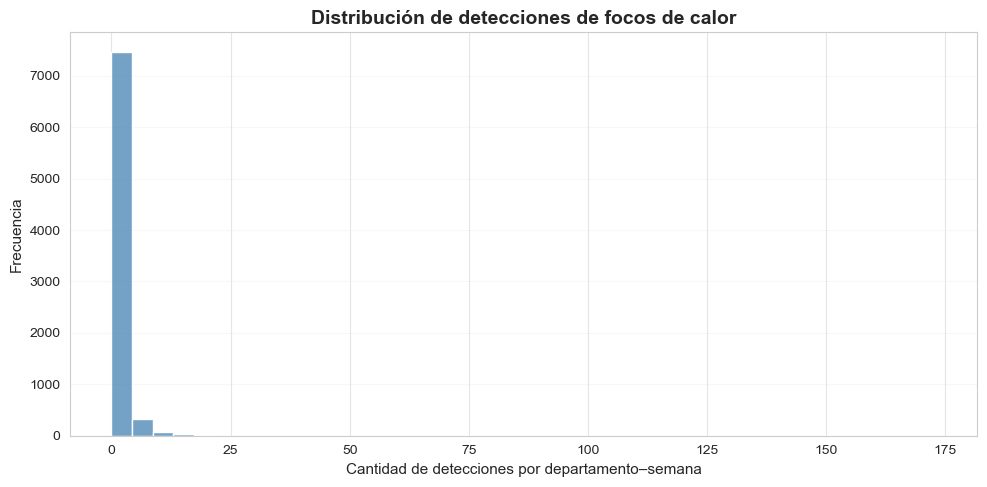

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=datos,
    x="cantidad_detecciones",
    bins=40,
    color="steelblue"
)

plt.title("Distribución de detecciones de focos de calor")
plt.xlabel("Cantidad de detecciones por departamento–semana")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
q1 = datos["cantidad_detecciones"].quantile(0.25)
q3 = datos["cantidad_detecciones"].quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print("Límite superior de valores atípicos:", limite_superior)

Límite superior de valores atípicos: 2.5


In [11]:
positivos = datos.loc[
    datos["cantidad_detecciones"] > 0,
    "cantidad_detecciones"
]

q1 = positivos.quantile(0.25)
q3 = positivos.quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print("Q1:", q1)
print("Mediana:", positivos.median())
print("Q3:", q3)
print("Límite superior:", limite_superior)
print("Máximo:", positivos.max())

Q1: 1.0
Mediana: 2.0
Q3: 3.0
Límite superior: 6.0
Máximo: 173


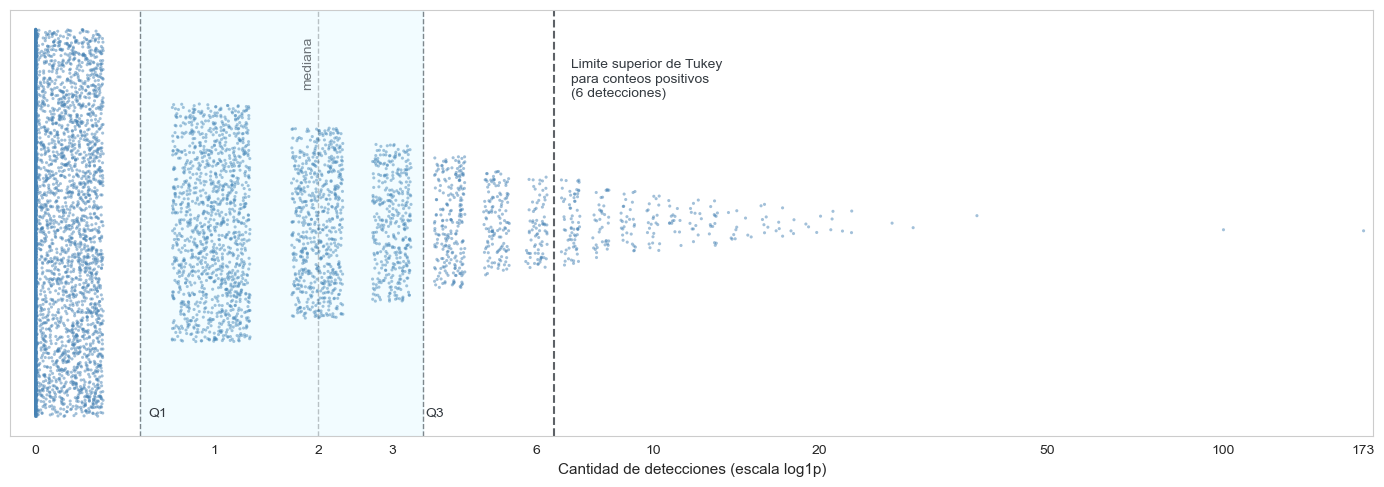

In [12]:
import numpy as np
import matplotlib.pyplot as plt

x = datos["cantidad_detecciones"].dropna().to_numpy()

# Frecuencia de cada cantidad de detecciones
valores, conteos = np.unique(x, return_counts=True)
frecuencias = dict(zip(valores, conteos))

# Dispersión vertical proporcional a la frecuencia
np.random.seed(42)

amplitud = np.array([
    (frecuencias[v] / conteos.max()) ** 0.35
    for v in x
])

y_jitter = np.random.uniform(-1, 1, len(x)) * amplitud
x_jitter = x + np.random.uniform(-0.30, 0.30, len(x))

fig, ax = plt.subplots(figsize=(14, 5))

# Transformar las posiciones horizontales
x_log = np.log1p(x_jitter.clip(min=0))

ax.scatter(
    x_log,    y_jitter,
    s=5,    alpha=0.50,
    color="steelblue",
    edgecolors="none"
)


ax.set_xticks(np.log1p([0, 1, 2, 3, 6, 10, 20, 50, 100, 173]))
ax.set_xticklabels(["0", "1", "2", "3", "6", "10", "20", "50", "100", "173"])

ax.set_xlim(-0.1, np.log1p(180))
ax.set_xlabel("Cantidad de detecciones (escala log1p)")


ax.set_ylabel("")
ax.set_yticks([])
ax.grid(False)

#ax.spines["left"].set_visible(False)

ax.axvline(
    x=np.log1p(6.5),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1.5,
    alpha=0.8
)

ax.text(
    np.log1p(7), 0.65,
    "Limite superior de Tukey""\n"
    "para conteos positivos""\n"
    "(6 detecciones)",
    color=UTEC_OSCURO,
    fontsize=10
)
#----------------------q1
ax.axvline(
    x=np.log1p(0.5),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)
ax.text(
    np.log1p(0.55), -1,
    "Q1",
    color=UTEC_OSCURO,
    fontsize=10
)
#-----------------------------
#----------------------q3
ax.axvline(
    x=np.log1p(3.5),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)
ax.text(
    np.log1p(3.55), -1,
    "Q3",
    color=UTEC_OSCURO,
    fontsize=10
)
#-----------------------------mediana
ax.axvline(
    x=np.log1p(2),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1,
    alpha=0.3
)
ax.text(
    np.log1p(1.82),0.7,
    "mediana", rotation=90,
    color=UTEC_OSCURO,
    fontsize=10,alpha=0.7
)
#-----------------------------

ax.axvspan(
    np.log1p(0.5), np.log1p(3.5),
    color=UTEC_CELESTE,
    alpha=0.10
)

#ax.set_title("Distribución de detecciones de focos de calor por departamento-semana")
plt.savefig(
    "cant_detecciones.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.tight_layout()
plt.show()

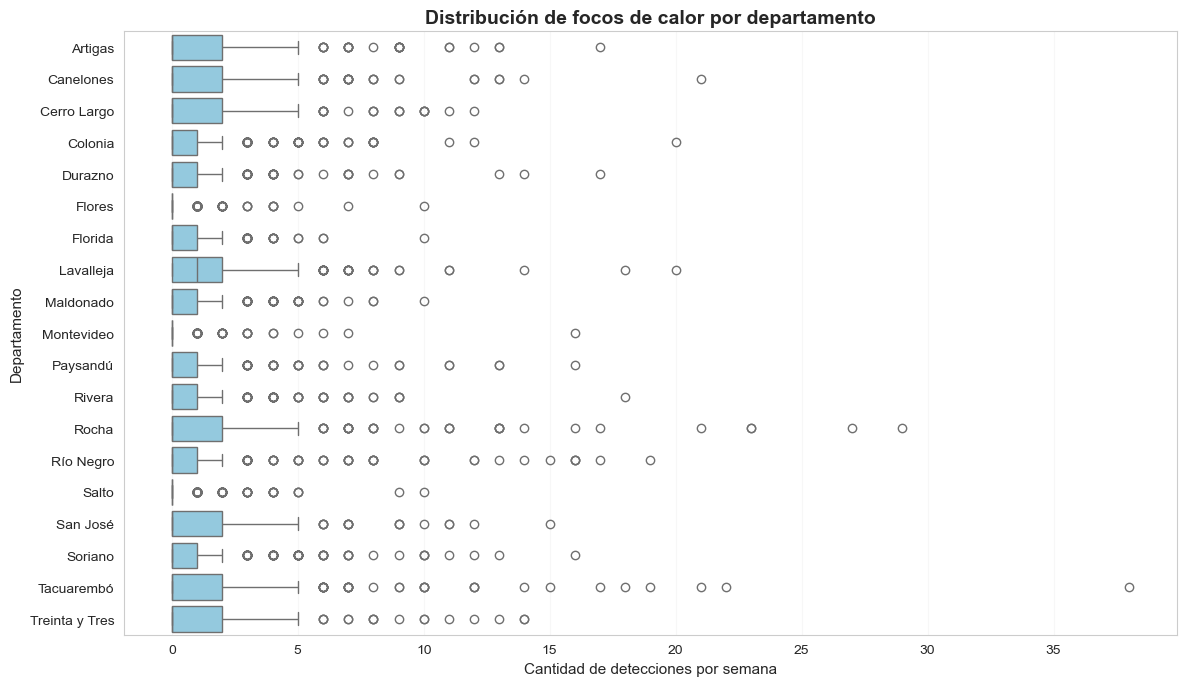

In [13]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=datos[datos["cantidad_detecciones"]<50],
    x="cantidad_detecciones",
    y="departamento",
    color="skyblue"
)

plt.title("Distribución de focos de calor por departamento")
plt.xlabel("Cantidad de detecciones por semana")
plt.ylabel("Departamento")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

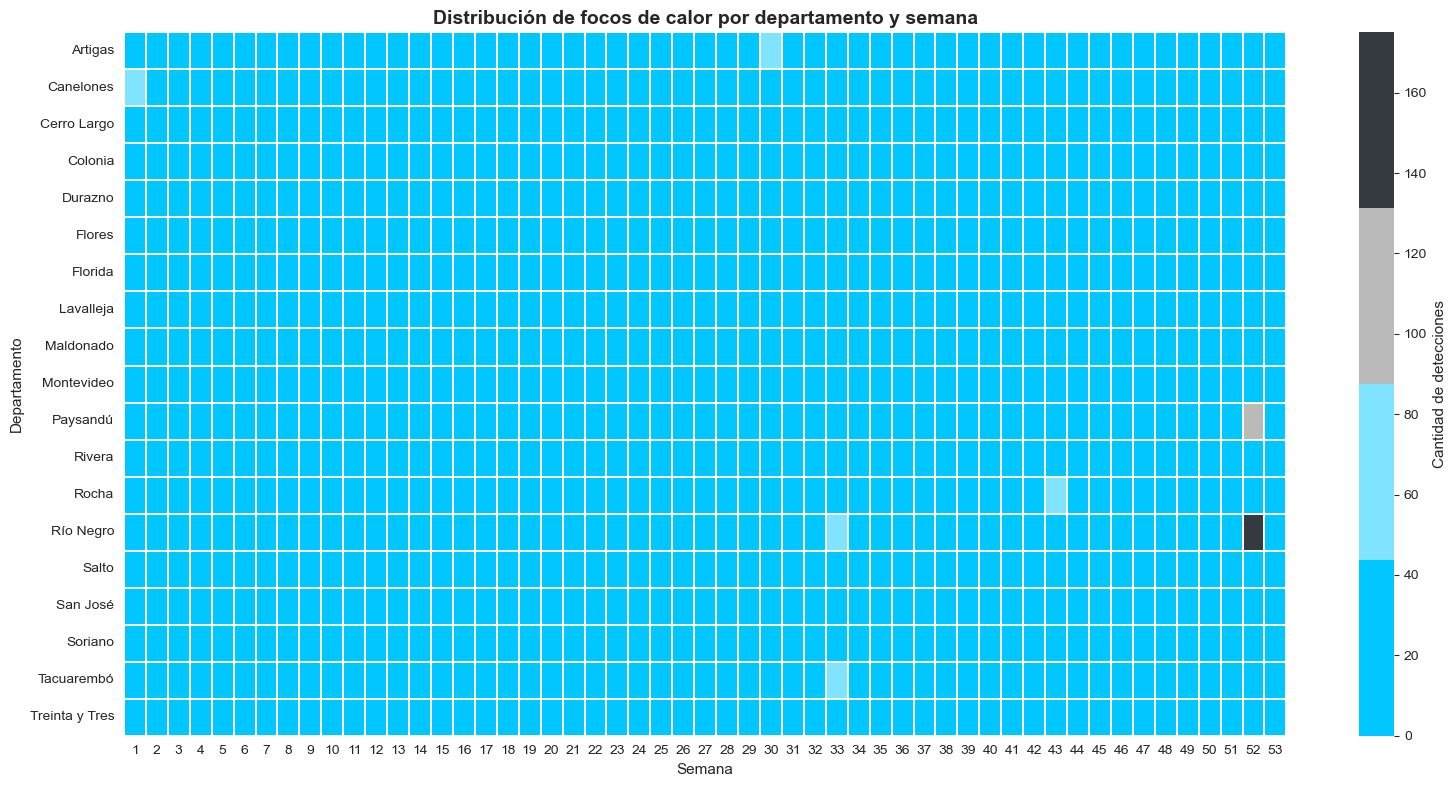

In [14]:
import pandas as pd

# Convertir la columna a numérica
datos["cantidad_detecciones"] = pd.to_numeric(
    datos["cantidad_detecciones"],
    errors="coerce"
)

# Crear tabla para el mapa de calor
tabla_heatmap = datos.pivot_table(
    index="departamento",
    columns="numero_semana",
    values="cantidad_detecciones",
    aggfunc="sum",
    fill_value=0
)

tabla_heatmap = tabla_heatmap.sort_index(axis=1)

# Generar gráfico
plt.figure(figsize=(16, 8))

sns.heatmap(
    tabla_heatmap.astype(float),
    cmap=PALETA_UTEC,
    linewidths=0.2,
    cbar_kws={"label": "Cantidad de detecciones"}
)

plt.title("Distribución de focos de calor por departamento y semana")
plt.xlabel("Semana")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

# Analisis de variables meteorologicas por cluster

In [16]:
file = r"/Users/marialujaniglesias/Downloads/dataset_modelado_nivel_actividad_firms.parquet"
data = pd.read_parquet(file)
data.shape

(7923, 19)

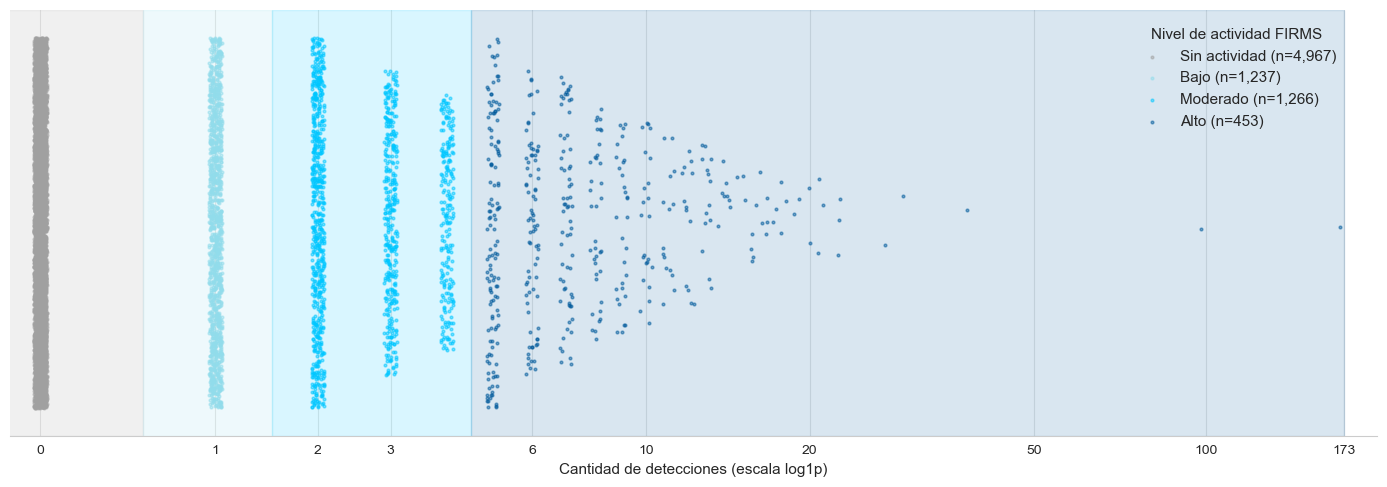

In [17]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Separar los cuatro niveles
sin_actividad = data.loc[
    data["nivel_actividad_firms"] == "Sin actividad",
    "cantidad_detecciones"
].dropna()

bajo = data.loc[
    data["nivel_actividad_firms"] == "Bajo",
    "cantidad_detecciones"
].dropna()

moderado = data.loc[
    data["nivel_actividad_firms"] == "Moderado",
    "cantidad_detecciones"
].dropna()

alto = data.loc[
    data["nivel_actividad_firms"] == "Alto",
    "cantidad_detecciones"
].dropna()


# Frecuencias para controlar la dispersión vertical
f0 = sin_actividad.value_counts()
f1 = bajo.value_counts()
f2 = moderado.value_counts()
f3 = alto.value_counts()

# Coordenadas con jitter horizontal y vertical
x0 = np.log1p(sin_actividad.to_numpy()) + rng.uniform(-0.025, 0.025, len(sin_actividad))
y0 = rng.uniform(-1, 1, len(sin_actividad)) * (sin_actividad.map(f0) / f0.max()).to_numpy() ** 0.35

x1 = np.log1p(bajo.to_numpy()) + rng.uniform(-0.025, 0.025, len(bajo))
y1 = rng.uniform(-1, 1, len(bajo)) * (bajo.map(f1) / f1.max()).to_numpy() ** 0.35

x2 = np.log1p(moderado.to_numpy()) + rng.uniform(-0.025, 0.025, len(moderado))
y2 = rng.uniform(-1, 1, len(moderado)) * (moderado.map(f2) / f2.max()).to_numpy() ** 0.35

x3 = np.log1p(alto.to_numpy()) + rng.uniform(-0.025, 0.025, len(alto))
y3 = rng.uniform(-1, 1, len(alto)) * (alto.map(f3) / f3.max()).to_numpy() ** 0.35


# Crear figura
fig, ax = plt.subplots(figsize=(14, 5))

# ---------------------------------
# ÁREAS SOMBREADAS (EDITABLES)
# Límites ilustrativos: ajustar a los reales
# ---------------------------------

ax.axvspan(-1, np.log1p(0.5),
           color="#A0A0A0", alpha=0.15)

ax.axvspan(np.log1p(0.5), np.log1p(1.5),
           color="#91DCEB", alpha=0.15)

ax.axvspan(np.log1p(1.5), np.log1p(4.5),
           color="#00C7FF", alpha=0.15)

ax.axvspan(np.log1p(4.5), np.log1p(173),
           color="#005A9C", alpha=0.15)


# ---------------------------------
# PUNTOS DE CADA CLUSTER
# ---------------------------------

ax.scatter(x0, y0, s=4, alpha=0.5,
           color="#A0A0A0",
           label=f"Sin actividad (n={len(sin_actividad):,})")

ax.scatter(x1, y1, s=4, alpha=0.5,
           color="#91DCEB",
           label=f"Bajo (n={len(bajo):,})")

ax.scatter(x2, y2, s=4, alpha=0.5,
           color="#00C7FF",
           label=f"Moderado (n={len(moderado):,})")

ax.scatter(x3, y3, s=4, alpha=0.5,
           color="#005A9C",
           label=f"Alto (n={len(alto):,})")


# ---------------------------------
# FORMATO
# ---------------------------------

ticks = [0, 1, 2, 3, 6, 10, 20, 50, 100, 173]

ax.set_xticks(np.log1p(ticks))
ax.set_xticklabels(ticks)

ax.set_xlim(-0.12, np.log1p(175) + 0.12)
ax.set_ylim(-1.15, 1.15)

ax.set_xlabel("Cantidad de detecciones (escala log1p)", fontsize=11)
ax.set_yticks([])

ax.legend(
    title="Nivel de actividad FIRMS",
    loc="upper right",
    bbox_to_anchor=(0.98, 0.99),
    frameon=False
)

ax.spines[["top", "right", "left"]].set_visible(False)

plt.savefig(
    "plot_clusters.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.tight_layout()
plt.show()

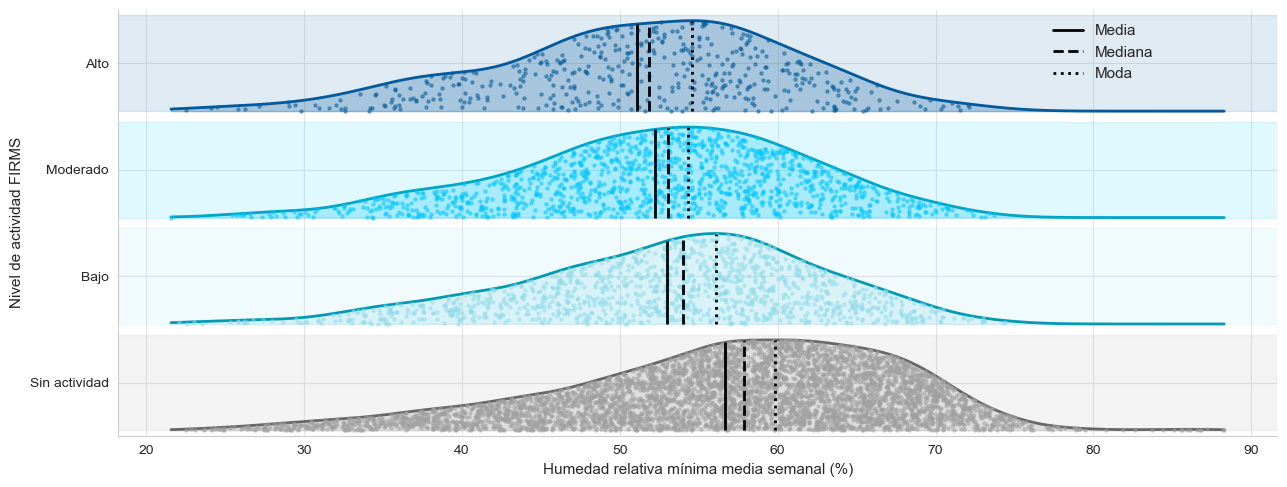

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "relative_humidity_2m_min_mean_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin actividad", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Bajo", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Moderado", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Alto", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color="#A0A0A0", alpha=0.12)
ax.axhspan(0.55, 1.45, color="#91DCEB", alpha=0.12)
ax.axhspan(1.55, 2.45, color="#00C7FF", alpha=0.12)
ax.axhspan(2.55, 3.45, color="#005A9C", alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color="#A0A0A0", zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color="#91DCEB", zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color="#00C7FF", zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color="#005A9C", zorder=3)



# Distribuciones simétricas por cluster

# Sin actividad
ax.fill_between(xx, -0.45, -0.45 + d0, color="#A0A0A0", alpha=0.25)
ax.plot(xx, -0.45 + d0, color="#666666", lw=2)

# Bajo
ax.fill_between(xx, 0.55, 0.55 + d1, color="#91DCEB", alpha=0.25)
ax.plot(xx, 0.55 + d1, color="#009AB5", lw=2)

# Moderado
ax.fill_between(xx, 1.55, 1.55 + d2, color="#00C7FF", alpha=0.25)
ax.plot(xx, 1.55 + d2, color="#00A6C8", lw=2)

# Alto
ax.fill_between(xx, 2.55, 2.55 + d3, color="#005A9C", alpha=0.25)
ax.plot(xx, 2.55 + d3, color="#005A9C", lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin actividad
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Bajo
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Moderado
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Alto
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin actividad", "Bajo", "Moderado", "Alto"])

ax.set_ylim(-0.5, 3.5)
#ax.set_xlim(4,7)

ax.set_xlabel("Humedad relativa mínima media semanal (%)")
ax.set_ylabel("Nivel de actividad FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
#plt.savefig(    "plot_clusters_humedad.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

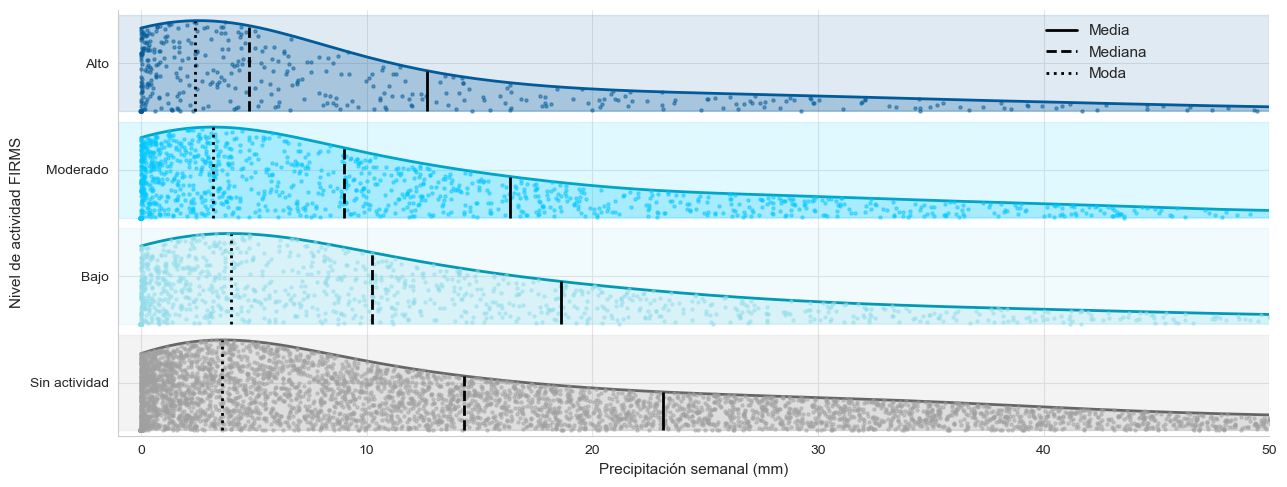

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "precipitation_sum_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin actividad", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Bajo", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Moderado", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Alto", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color="#A0A0A0", alpha=0.12)
ax.axhspan(0.55, 1.45, color="#91DCEB", alpha=0.12)
ax.axhspan(1.55, 2.45, color="#00C7FF", alpha=0.12)
ax.axhspan(2.55, 3.45, color="#005A9C", alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color="#A0A0A0", zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color="#91DCEB", zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color="#00C7FF", zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color="#005A9C", zorder=3)



# Distribuciones simétricas por cluster

# Sin actividad
ax.fill_between(xx, -0.45, -0.45 + d0, color="#A0A0A0", alpha=0.25)
ax.plot(xx, -0.45 + d0, color="#666666", lw=2)

# Bajo
ax.fill_between(xx, 0.55, 0.55 + d1, color="#91DCEB", alpha=0.25)
ax.plot(xx, 0.55 + d1, color="#009AB5", lw=2)

# Moderado
ax.fill_between(xx, 1.55, 1.55 + d2, color="#00C7FF", alpha=0.25)
ax.plot(xx, 1.55 + d2, color="#00A6C8", lw=2)

# Alto
ax.fill_between(xx, 2.55, 2.55 + d3, color="#005A9C", alpha=0.25)
ax.plot(xx, 2.55 + d3, color="#005A9C", lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin actividad
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Bajo
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Moderado
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Alto
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin actividad", "Bajo", "Moderado", "Alto"])

ax.set_ylim(-0.5, 3.5)
ax.set_xlim(-1,50)

ax.set_xlabel("Precipitación semanal (mm)")
ax.set_ylabel("Nivel de actividad FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    "plot_clusters_precip.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

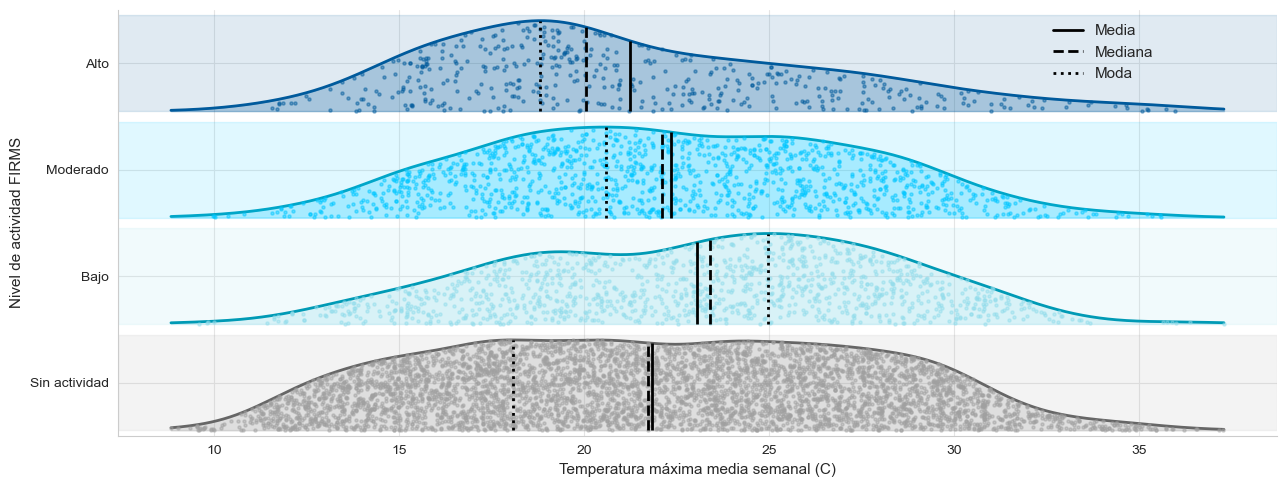

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "temperature_2m_max_mean_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin actividad", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Bajo", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Moderado", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Alto", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color="#A0A0A0", alpha=0.12)
ax.axhspan(0.55, 1.45, color="#91DCEB", alpha=0.12)
ax.axhspan(1.55, 2.45, color="#00C7FF", alpha=0.12)
ax.axhspan(2.55, 3.45, color="#005A9C", alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color="#A0A0A0", zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color="#91DCEB", zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color="#00C7FF", zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color="#005A9C", zorder=3)



# Distribuciones simétricas por cluster

# Sin actividad
ax.fill_between(xx, -0.45, -0.45 + d0, color="#A0A0A0", alpha=0.25)
ax.plot(xx, -0.45 + d0, color="#666666", lw=2)

# Bajo
ax.fill_between(xx, 0.55, 0.55 + d1, color="#91DCEB", alpha=0.25)
ax.plot(xx, 0.55 + d1, color="#009AB5", lw=2)

# Moderado
ax.fill_between(xx, 1.55, 1.55 + d2, color="#00C7FF", alpha=0.25)
ax.plot(xx, 1.55 + d2, color="#00A6C8", lw=2)

# Alto
ax.fill_between(xx, 2.55, 2.55 + d3, color="#005A9C", alpha=0.25)
ax.plot(xx, 2.55 + d3, color="#005A9C", lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin actividad
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Bajo
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Moderado
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Alto
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin actividad", "Bajo", "Moderado", "Alto"])

ax.set_ylim(-0.5, 3.5)
#ax.set_xlim(-1,50)

ax.set_xlabel("Temperatura máxima media semanal (C)")
ax.set_ylabel("Nivel de actividad FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    "plot_clusters_temperatura.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

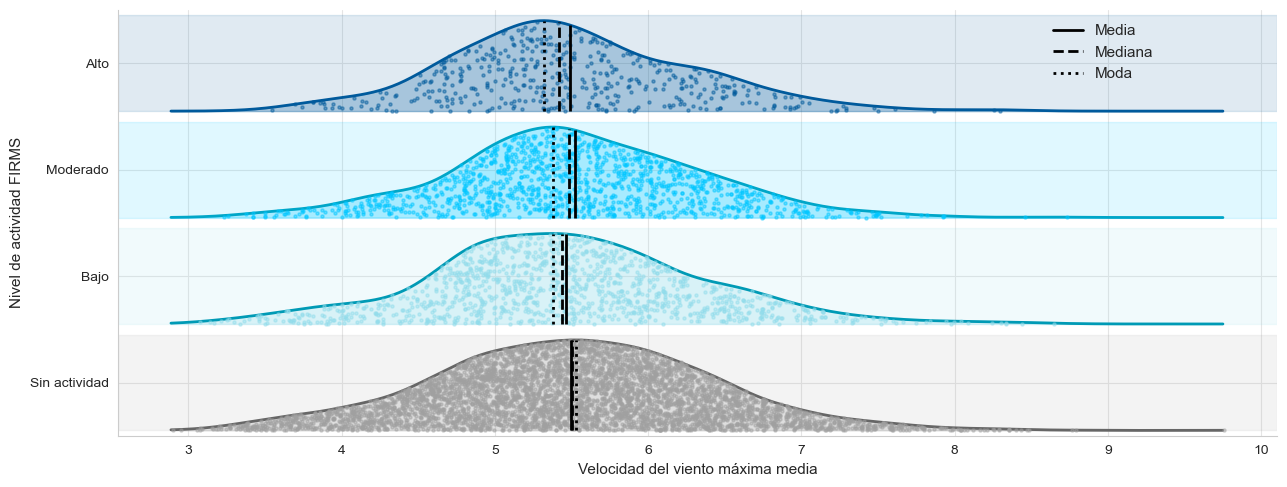

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "wind_speed_10m_max_mean_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin actividad", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Bajo", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Moderado", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Alto", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color="#A0A0A0", alpha=0.12)
ax.axhspan(0.55, 1.45, color="#91DCEB", alpha=0.12)
ax.axhspan(1.55, 2.45, color="#00C7FF", alpha=0.12)
ax.axhspan(2.55, 3.45, color="#005A9C", alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color="#A0A0A0", zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color="#91DCEB", zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color="#00C7FF", zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color="#005A9C", zorder=3)



# Distribuciones simétricas por cluster

# Sin actividad
ax.fill_between(xx, -0.45, -0.45 + d0, color="#A0A0A0", alpha=0.25)
ax.plot(xx, -0.45 + d0, color="#666666", lw=2)

# Bajo
ax.fill_between(xx, 0.55, 0.55 + d1, color="#91DCEB", alpha=0.25)
ax.plot(xx, 0.55 + d1, color="#009AB5", lw=2)

# Moderado
ax.fill_between(xx, 1.55, 1.55 + d2, color="#00C7FF", alpha=0.25)
ax.plot(xx, 1.55 + d2, color="#00A6C8", lw=2)

# Alto
ax.fill_between(xx, 2.55, 2.55 + d3, color="#005A9C", alpha=0.25)
ax.plot(xx, 2.55 + d3, color="#005A9C", lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin actividad
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Bajo
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Moderado
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Alto
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin actividad", "Bajo", "Moderado", "Alto"])

ax.set_ylim(-0.5, 3.5)
#ax.set_xlim(-1,50)

ax.set_xlabel("Velocidad del viento máxima media")
ax.set_ylabel("Nivel de actividad FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    "plot_clusters_viento.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

# MAPA

In [24]:
firms = pd.read_parquet(
    "/Users/marialujaniglesias/Documents/PAA_katerin_pedro/firms_2018_2025.parquet"
)
firms = firms[firms["pais_codigo"] =="URY"]


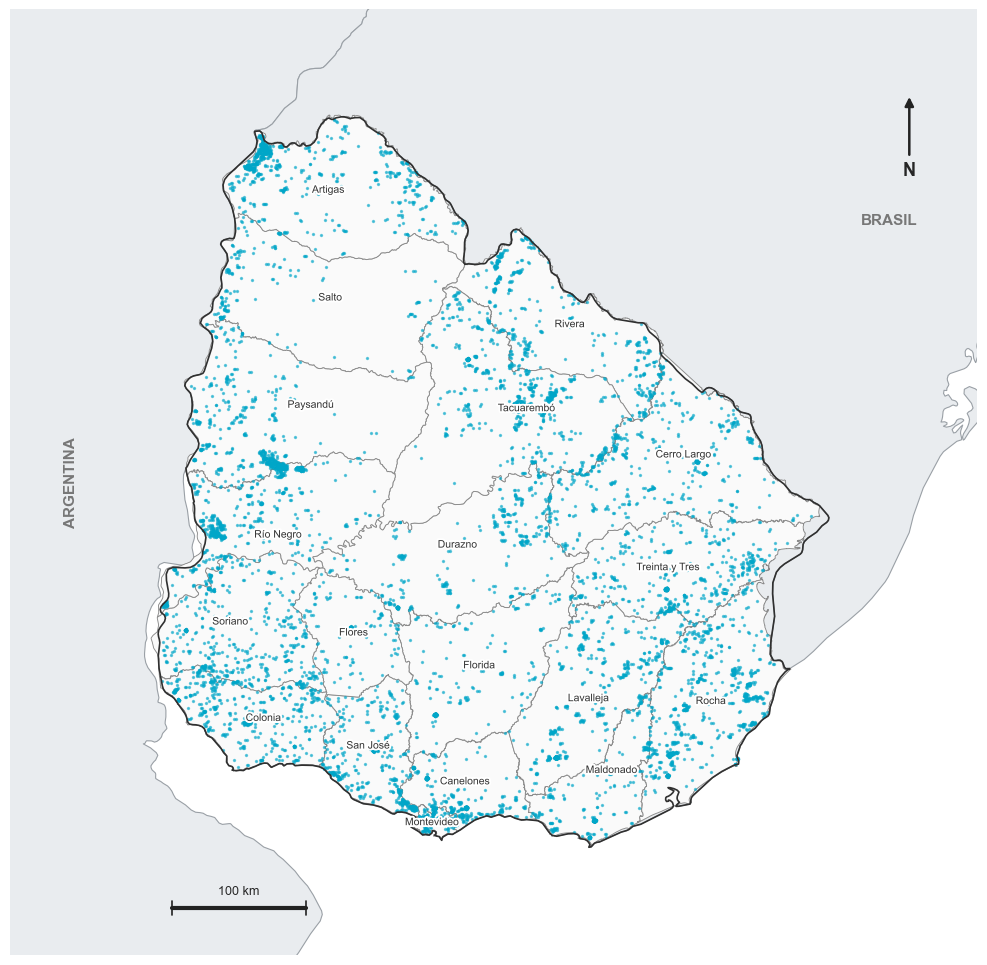

In [25]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import requests

# -----------------------------------
# 1. Cargar países
# -----------------------------------
url_paises = (
    "https://naturalearth.s3.amazonaws.com/"
    "10m_cultural/ne_10m_admin_0_countries.zip"
)

paises = gpd.read_file(url_paises)

region = paises[
    paises["ADMIN"].isin(["Uruguay", "Argentina", "Brazil", "Paraguay"])
].copy()

# -----------------------------------
# 2. Cargar departamentos de Uruguay
# -----------------------------------
url_api = "https://www.geoboundaries.org/api/current/gbOpen/URY/ADM1/"

respuesta = requests.get(url_api, timeout=30)
respuesta.raise_for_status()

info = respuesta.json()
departamentos = gpd.read_file(info["gjDownloadURL"])

# -----------------------------------
# 3. Crear puntos FIRMS
# -----------------------------------
puntos = gpd.GeoDataFrame(
    firms.dropna(subset=["latitud", "longitud"]).copy(),
    geometry=gpd.points_from_xy(
        firms.dropna(subset=["latitud", "longitud"])["longitud"],
        firms.dropna(subset=["latitud", "longitud"])["latitud"]
    ),
    crs="EPSG:4326"
)

# Proyección en metros
crs = "EPSG:32721"

region = region.to_crs(crs)
departamentos = departamentos.to_crs(crs)
puntos = puntos.to_crs(crs)

uruguay = region[region["ADMIN"] == "Uruguay"]

# -----------------------------------
# 4. Crear figura
# -----------------------------------
fig, ax = plt.subplots(figsize=(10, 12))

# Países limítrofes
region.plot(
    ax=ax,
    color="#E9ECEF",
    edgecolor="#9AA0A6",
    linewidth=0.8,
    zorder=1
)

# Uruguay y sus departamentos
departamentos.plot(
    ax=ax,
    color="#FAFAFA",
    edgecolor="#8A8A8A",
    linewidth=0.65,
    zorder=2
)

# Detecciones FIRMS
puntos.plot(
    ax=ax,
    color="#00A6C8",
    markersize=2,
    alpha=0.55,
    zorder=3
)

# Contorno nacional
uruguay.boundary.plot(
    ax=ax,
    color="#303030",
    linewidth=1.2,
    zorder=4
)

# -----------------------------------
# 5. Nombres de departamentos
# -----------------------------------
col_nombre = "shapeName"

for _, fila in departamentos.iterrows():
    centro = fila.geometry.representative_point()

    ax.text(
        centro.x,
        centro.y,
        fila[col_nombre],
        fontsize=7.5,
        ha="center",
        va="center",
        color="#333333",
        fontweight="medium",
        path_effects=[
            pe.withStroke(linewidth=2.8, foreground="white")
        ],
        zorder=5
    )

# -----------------------------------
# 6. Extensión del mapa
# -----------------------------------
xmin, ymin, xmax, ymax = uruguay.total_bounds

margen_x = 110000
margen_y = 80000

ax.set_xlim(xmin - margen_x, xmax + margen_x)
ax.set_ylim(ymin - margen_y, ymax + margen_y)

# -----------------------------------
# 7. Nombres de países limítrofes
# -----------------------------------
ax.text(
    xmin - 65000,
    (ymin + ymax) / 2,
    "ARGENTINA",
    fontsize=11,
    fontweight="bold",
    color="#777777",
    rotation=90,
    ha="center",
    va="center"
)

ax.text(
    xmax + 45000,
    ymax - 80000,
    "BRASIL",
    fontsize=11,
    fontweight="bold",
    color="#777777",
    ha="center"
)

# -----------------------------------
# 8. Flecha norte
# -----------------------------------
ax.annotate(
    "N",
    xy=(0.93, 0.91),
    xytext=(0.93, 0.83),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-|>",
        color="#222222",
        lw=1.8
    )
)

# -----------------------------------
# 9. Escala gráfica: 100 km
# -----------------------------------
x0 = xmin + 10000
y0 = ymin - 45000
escala = 100000

ax.plot(
    [x0, x0 + escala],
    [y0, y0],
    color="#222222",
    linewidth=3
)

for x in [x0, x0 + escala]:
    ax.plot(
        [x, x],
        [y0 - 5000, y0 + 5000],
        color="#222222",
        linewidth=1.2
    )

ax.text(
    x0 + escala / 2,
    y0 + 10000,
    "100 km",
    fontsize=9,
    ha="center"
)

# -----------------------------------
# 10. Título y exportación
# -----------------------------------
#ax.set_title(
#    "Distribución espacial de las detecciones FIRMS\n"
#    "Uruguay, 2018–2025",
#    fontsize=15,
#    fontweight="bold",
#    pad=20
#)

#ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_firms_uruguay.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()